In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv(r"C:\Users\ASUS\Downloads\DAML dataset\tech_advertising_campaigns_dataset.csv")

In [3]:
df.head()

,campaign_id,campaign_objective,platform,ad_placement,device_type,operating_system,creative_format,creative_size,ad_copy_length,has_call_to_action,creative_emotion,creative_age_days,target_audience_age,target_audience_gender,audience_interest_category,income_bracket,purchase_intent_score,retargeting_flag,start_date,quarter,day_of_week,hour_of_day,campaign_day,quality_score,actual_cpc,impressions,clicks,conversions,ad_spend,revenue,bounce_rate,avg_session_duration_seconds,pages_per_session,industry_vertical,budget_tier,CTR,CPC,conversion_rate,CPA,ROAS,profit
0,CAMP_00001,Lead Generation,Facebook,Search,Mobile,Android,Text,728x90,Short,False,Curiosity,72,45-54,Female,Shoppers,<$50K,Medium,False,2024-03-06,1,Wednesday,18,34,5,2.23,66329,402,2,896.46,289.67,67.75,70,2.00,E-commerce,High,0.606,2.23,0.498,448.23,0.32,-606.79
1,CAMP_00002,Engagement,Facebook,Feed,Mobile,iOS,Image,320x50,Long,True,Neutral,62,65+,Female,Business Professionals,$50K-$100K,Medium,False,2024-01-26,1,Friday,6,22,5,2.48,50094,467,5,1158.16,1728.20,63.73,105,2.74,Finance,Medium,0.932,2.48,1.071,231.63,1.49,570.04
2,CAMP_00003,Conversions,Google Ads,Feed,Tablet,iOS,Video,1920x1080,Short,False,Urgency,79,65+,Male,Tech Enthusiasts,<$50K,High,False,2025-05-15,2,Thursday,1,32,4,3.88,10842,112,6,434.56,2903.26,31.93,149,3.97,Healthcare,Low,1.033,3.88,5.357,72.43,6.68,2468.70
3,CAMP_00004,Conversions,LinkedIn,Search,Desktop,iOS,Carousel,1920x1080,Short,False,Joy,57,35-44,All,Shoppers,<$50K,Low,False,2024-07-21,3,Sunday,7,32,4,8.29,7820,123,3,1019.67,502.28,65.52,147,2.49,Education,Medium,1.573,8.29,2.439,339.89,0.49,-517.39
4,CAMP_00005,Brand Awareness,Facebook,Stories,Mobile,iOS,Image,1920x1080,Short,False,Joy,17,25-34,Female,Students,$100K-$200K,Low,False,2025-03-09,1,Sunday,17,52,7,1.41,21436,302,0,425.82,0.00,68.95,81,3.04,SaaS,Low,1.409,1.41,0.000,0.00,0.00,-425.82


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 41


In [5]:
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. campaign_id
2. campaign_objective
3. platform
4. ad_placement
5. device_type
6. operating_system
7. creative_format
8. creative_size
9. ad_copy_length
10. has_call_to_action
11. creative_emotion
12. creative_age_days
13. target_audience_age
14. target_audience_gender
15. audience_interest_category
16. income_bracket
17. purchase_intent_score
18. retargeting_flag
19. start_date
20. quarter
21. day_of_week
22. hour_of_day
23. campaign_day
24. quality_score
25. actual_cpc
26. impressions
27. clicks
28. conversions
29. ad_spend
30. revenue
31. bounce_rate
32. avg_session_duration_seconds
33. pages_per_session
34. industry_vertical
35. budget_tier
36. CTR
37. CPC
38. conversion_rate
39. CPA
40. ROAS
41. profit


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 41 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   campaign_id                   10000 non-null  object 
 1   campaign_objective            10000 non-null  object 
 2   platform                      10000 non-null  object 
 3   ad_placement                  10000 non-null  object 
 4   device_type                   10000 non-null  object 
 5   operating_system              10000 non-null  object 
 6   creative_format               10000 non-null  object 
 7   creative_size                 10000 non-null  object 
 8   ad_copy_length                10000 non-null  object 
 9   has_call_to_action            10000 non-null  bool   
 10  creative_emotion              10000 non-null  object 
 11  creative_age_days             10000 non-null  int64  
 12  target_audience_age           10000 non-null  object 
 13  ta

In [7]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

Total missing values: 0


In [8]:
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 0


In [9]:
df.describe()

,creative_age_days,quarter,hour_of_day,campaign_day,quality_score,actual_cpc,impressions,clicks,conversions,ad_spend,revenue,bounce_rate,avg_session_duration_seconds,pages_per_session,CTR,CPC,conversion_rate,CPA,ROAS,profit
count,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04
mean,45.3743,2.419100,11.482500,45.429700,5.527400,3.290336,70539.223000,1526.436100,65.568800,4345.566179,2.841577e+04,52.528500,100.956600,3.113223,2.314340,3.290336,3.644033,190.895894,7.524918,2.407020e+04
std,26.1711,1.132424,6.932308,26.071107,1.553541,2.453852,91339.733246,2412.164582,183.404876,6917.481037,8.928461e+04,17.706165,46.541295,1.369884,1.573316,2.453852,4.354338,295.614462,14.985237,8.641610e+04
min,1.0000,1.000000,0.000000,1.000000,1.000000,0.300000,5000.000000,10.000000,0.000000,8.690000,0.000000e+00,10.000000,10.000000,1.000000,0.100000,0.300000,0.000000,0.000000,0.000000,-3.693984e+04
25%,22.0000,1.000000,5.000000,23.000000,4.000000,1.510000,16958.500000,290.000000,5.000000,666.307500,1.608910e+03,40.087500,68.000000,2.160000,1.172000,1.510000,1.005000,40.640000,1.197500,2.094800e+02
50%,45.0000,2.000000,12.000000,45.000000,6.000000,2.430000,37469.500000,718.000000,16.000000,1895.670000,6.099240e+03,53.580000,100.000000,2.830000,1.920000,2.430000,2.165500,99.460000,3.150000,3.302535e+03
75%,68.0000,3.000000,18.000000,68.000000,7.000000,4.530000,83213.750000,1746.000000,55.000000,4996.160000,2.216582e+04,65.472500,132.000000,3.740000,3.017250,4.530000,4.493250,225.457500,7.950000,1.664188e+04
max,90.0000,4.000000,23.000000,90.000000,10.000000,16.030000,500000.000000,40000.000000,5384.000000,49999.680000,2.800397e+06,90.000000,277.000000,8.510000,8.000000,16.030000,25.000000,6379.940000,487.300000,2.750398e+06


### Statistical Summary

The `describe()` function provides statistical information about the numerical variables in the dataset, including their central tendency, spread, and range.

In [10]:
# Numerical Columns
numerical_columns = df.select_dtypes(include=np.number).columns

print("Number of numerical columns:", len(numerical_columns))
print("\nNumerical columns:")
for column in numerical_columns:
    print("-", column)

Number of numerical columns: 20

Numerical columns:
- creative_age_days
- quarter
- hour_of_day
- campaign_day
- quality_score
- actual_cpc
- impressions
- clicks
- conversions
- ad_spend
- revenue
- bounce_rate
- avg_session_duration_seconds
- pages_per_session
- CTR
- CPC
- conversion_rate
- CPA
- ROAS
- profit


In [11]:
# Categorical Columns
categorical_columns = df.select_dtypes(include="object").columns

print("Number of categorical columns:", len(categorical_columns))
print("\nCategorical columns:")
for column in categorical_columns:
    print("-", column)

Number of categorical columns: 19

Categorical columns:
- campaign_id
- campaign_objective
- platform
- ad_placement
- device_type
- operating_system
- creative_format
- creative_size
- ad_copy_length
- creative_emotion
- target_audience_age
- target_audience_gender
- audience_interest_category
- income_bracket
- purchase_intent_score
- start_date
- day_of_week
- industry_vertical
- budget_tier


In [12]:
# Boolean Columns
boolean_columns = df.select_dtypes(include="bool").columns

print("Number of boolean columns:", len(boolean_columns))
print("\nBoolean columns:")
for column in boolean_columns:
    print("-", column)

Number of boolean columns: 2

Boolean columns:
- has_call_to_action
- retargeting_flag


In [13]:
for column in categorical_columns:
    print(f"\n{column}")
    print("Number of unique values:", df[column].nunique())


campaign_id
Number of unique values: 10000

campaign_objective
Number of unique values: 5

platform
Number of unique values: 6

ad_placement
Number of unique values: 6

device_type
Number of unique values: 3

operating_system
Number of unique values: 5

creative_format
Number of unique values: 6

creative_size
Number of unique values: 6

ad_copy_length
Number of unique values: 3

creative_emotion
Number of unique values: 6

target_audience_age
Number of unique values: 6

target_audience_gender
Number of unique values: 3

audience_interest_category
Number of unique values: 6

income_bracket
Number of unique values: 4

purchase_intent_score
Number of unique values: 3

start_date
Number of unique values: 761

day_of_week
Number of unique values: 7

industry_vertical
Number of unique values: 6

budget_tier
Number of unique values: 3


In [14]:
for column in categorical_columns:
    print(f"\n{'='*50}")
    print(column)
    print(f"{'='*50}")
    print(df[column].value_counts())


campaign_id
campaign_id
CAMP_09984    1
CAMP_09983    1
CAMP_09982    1
CAMP_09981    1
CAMP_09980    1
             ..
CAMP_00005    1
CAMP_00004    1
CAMP_00003    1
CAMP_00002    1
CAMP_00001    1
Name: count, Length: 10000, dtype: int64

campaign_objective
campaign_objective
Lead Generation    3563
Conversions        2946
Brand Awareness    2043
App Installs        746
Engagement          702
Name: count, dtype: int64

platform
platform
Google Ads    2933
Facebook      2527
LinkedIn      1468
TikTok        1213
Twitter       1029
Instagram      830
Name: count, dtype: int64

ad_placement
ad_placement
Feed               3491
Search             2067
Stories            1995
Display Network    1189
In-Stream Video     764
Sidebar             494
Name: count, dtype: int64

device_type
device_type
Mobile     5430
Desktop    3556
Tablet     1014
Name: count, dtype: int64

operating_system
operating_system
Android    2984
iOS        2550
Windows    2486
macOS      1501
Other       479
Nam

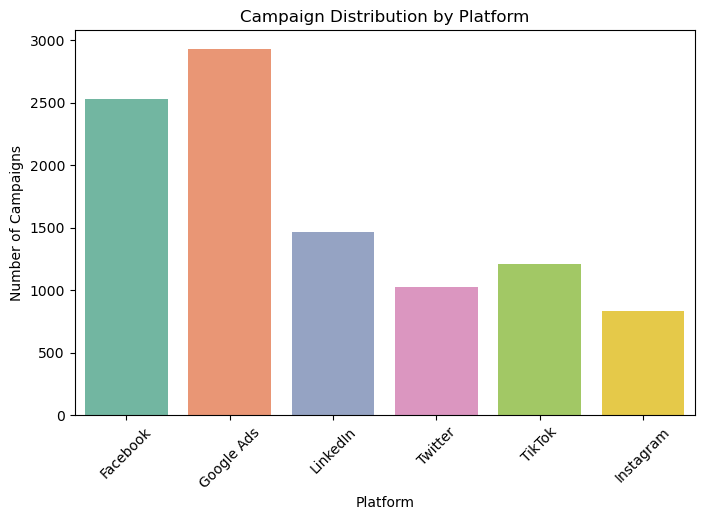

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="platform",
    hue="platform",
    palette="Set2",
    legend=False
)

plt.title("Campaign Distribution by Platform")
plt.xlabel("Platform")
plt.ylabel("Number of Campaigns")
plt.xticks(rotation=45)
plt.show()

This visualization shows how the marketing campaigns are distributed across different advertising platforms.

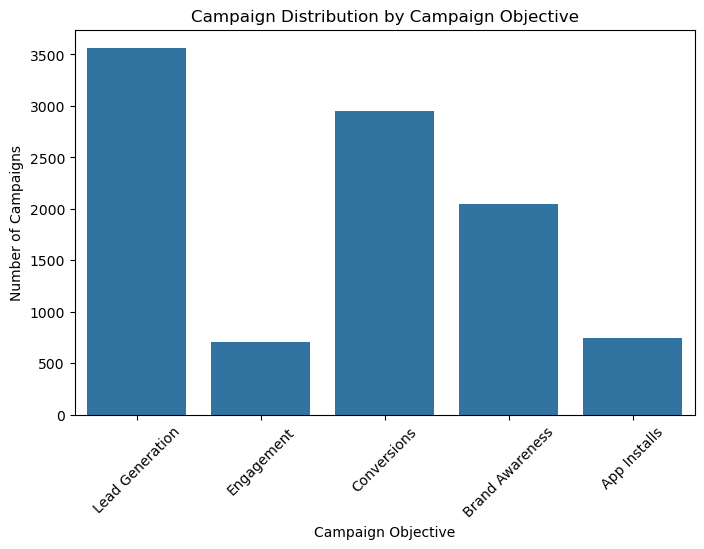

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="campaign_objective")

plt.title("Campaign Distribution by Campaign Objective")
plt.xlabel("Campaign Objective")
plt.ylabel("Number of Campaigns")
plt.xticks(rotation=45)
plt.show()

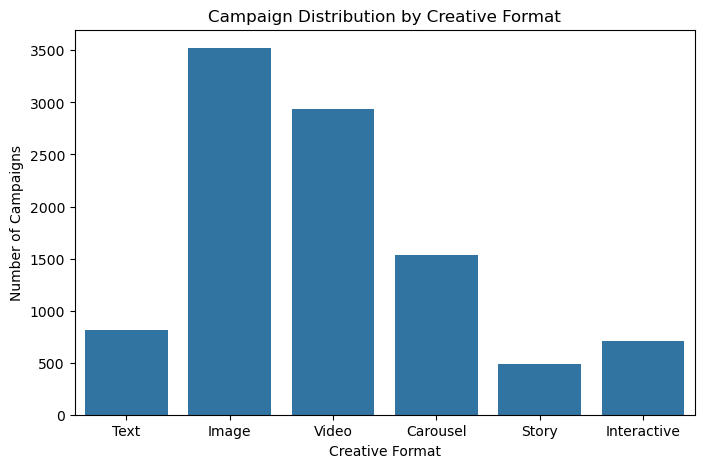

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="creative_format")

plt.title("Campaign Distribution by Creative Format")
plt.xlabel("Creative Format")
plt.ylabel("Number of Campaigns")
plt.show()

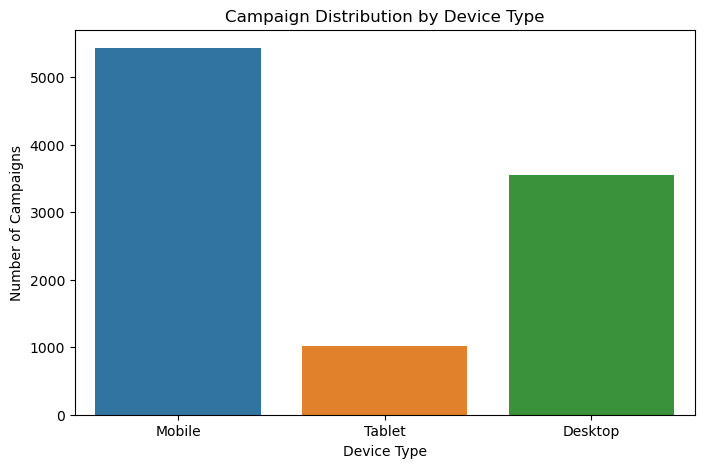

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="device_type",
    hue="device_type",
    legend=False
)

plt.title("Campaign Distribution by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Campaigns")
plt.show()

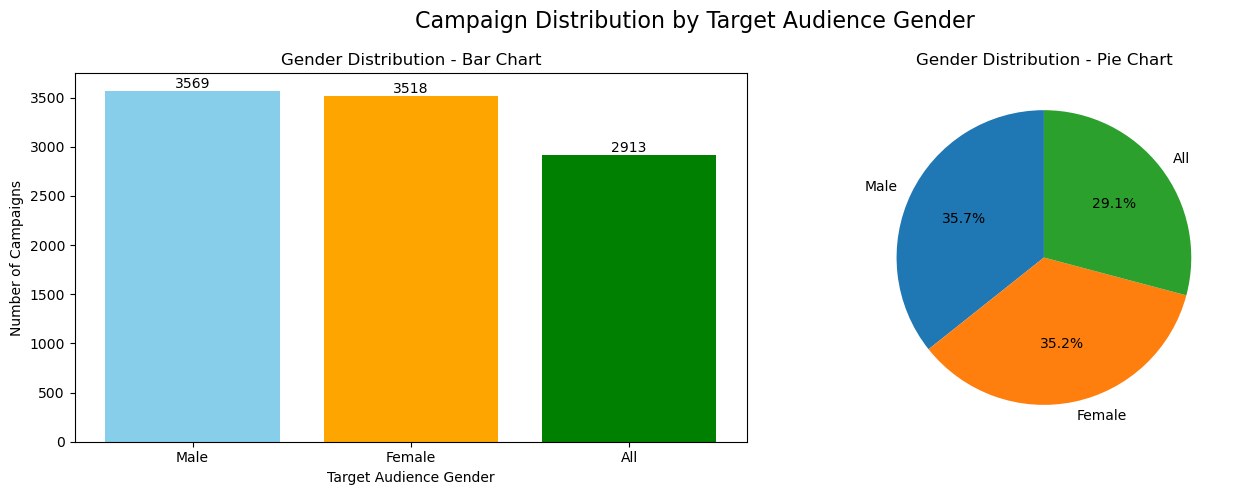

In [19]:
# Step 21 - Target Audience Gender
# Bar Chart + Pie Chart (1 x 2)

gender_counts = df["target_audience_gender"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------
# 1. Bar Chart
# -------------------------
bars = axes[0].bar(
    gender_counts.index,
    gender_counts.values,
    color=["skyblue", "orange", "green"]
)

axes[0].set_title("Gender Distribution - Bar Chart")
axes[0].set_xlabel("Target Audience Gender")
axes[0].set_ylabel("Number of Campaigns")

# Add values on top of bars
for bar in bars:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom"
    )

# -------------------------
# 2. Pie Chart
# -------------------------
axes[1].pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Gender Distribution - Pie Chart")

# Overall title
fig.suptitle(
    "Campaign Distribution by Target Audience Gender",
    fontsize=16
)

plt.tight_layout()
plt.show()

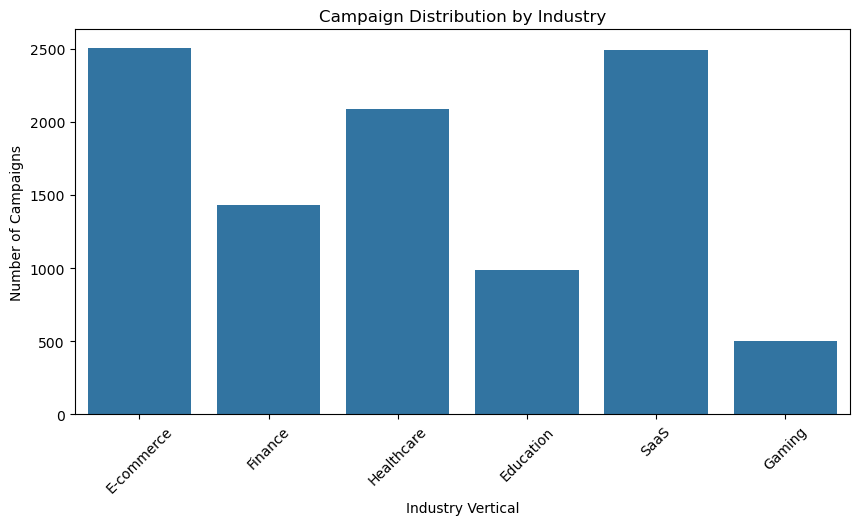

In [20]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="industry_vertical")

plt.title("Campaign Distribution by Industry")
plt.xlabel("Industry Vertical")
plt.ylabel("Number of Campaigns")
plt.xticks(rotation=45)
plt.show()

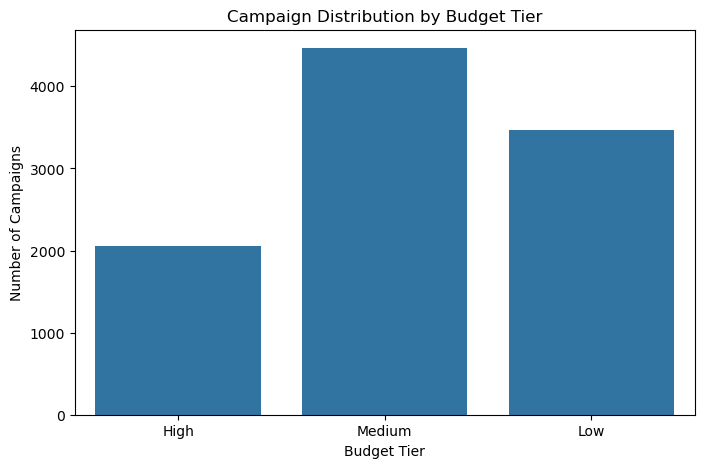

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="budget_tier")

plt.title("Campaign Distribution by Budget Tier")
plt.xlabel("Budget Tier")
plt.ylabel("Number of Campaigns")
plt.show()

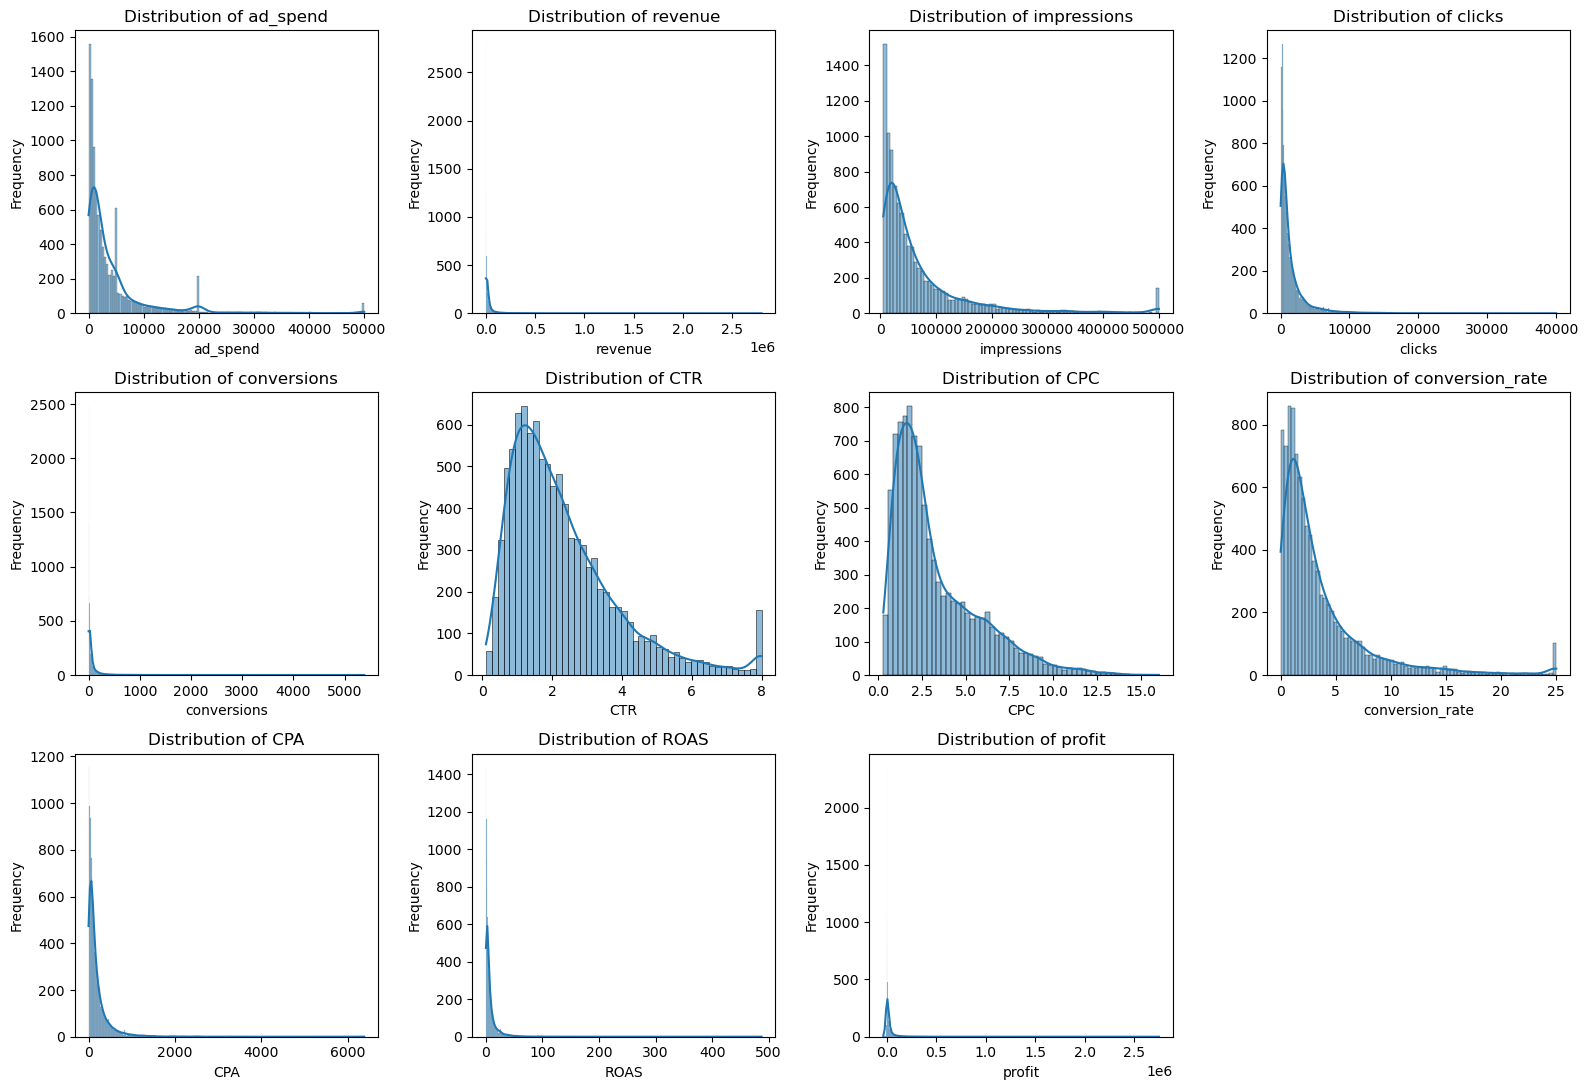

In [22]:
important_numeric = [
    "ad_spend",
    "revenue",
    "impressions",
    "clicks",
    "conversions",
    "CTR",
    "CPC",
    "conversion_rate",
    "CPA",
    "ROAS",
    "profit"
]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i, column in enumerate(important_numeric):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )
    
    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

# Hide unused subplot
for j in range(len(important_numeric), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### Numerical Distribution Analysis - Observations

The distributions of the numerical variables show that several marketing performance features are strongly right-skewed. Variables such as ad_spend, revenue, impressions, clicks, conversions, CPA, ROAS, and profit contain long right tails, indicating the presence of potentially extreme observations.

CTR, CPC, and conversion_rate show comparatively more concentrated distributions but still exhibit some degree of skewness.

These distributions indicate that outlier analysis is required before developing the preprocessing pipeline. Extreme observations will be investigated rather than automatically removed, since they may represent genuine high-performing or high-spending campaigns.

In [23]:
df[important_numeric].describe().T

,count,mean,std,min,25%,50%,75%,max
ad_spend,10000.0,4345.566179,6917.481037,8.69,666.3075,1895.6700,4996.16000,49999.68
revenue,10000.0,28415.770647,89284.609131,0.00,1608.9100,6099.2400,22165.82500,2800397.43
impressions,10000.0,70539.223000,91339.733246,5000.00,16958.5000,37469.5000,83213.75000,500000.00
clicks,10000.0,1526.436100,2412.164582,10.00,290.0000,718.0000,1746.00000,40000.00
conversions,10000.0,65.568800,183.404876,0.00,5.0000,16.0000,55.00000,5384.00
CTR,10000.0,2.314340,1.573316,0.10,1.1720,1.9200,3.01725,8.00
CPC,10000.0,3.290336,2.453852,0.30,1.5100,2.4300,4.53000,16.03
conversion_rate,10000.0,3.644033,4.354338,0.00,1.0050,2.1655,4.49325,25.00
CPA,10000.0,190.895894,295.614462,0.00,40.6400,99.4600,225.45750,6379.94
ROAS,10000.0,7.524918,14.985237,0.00,1.1975,3.1500,7.95000,487.30


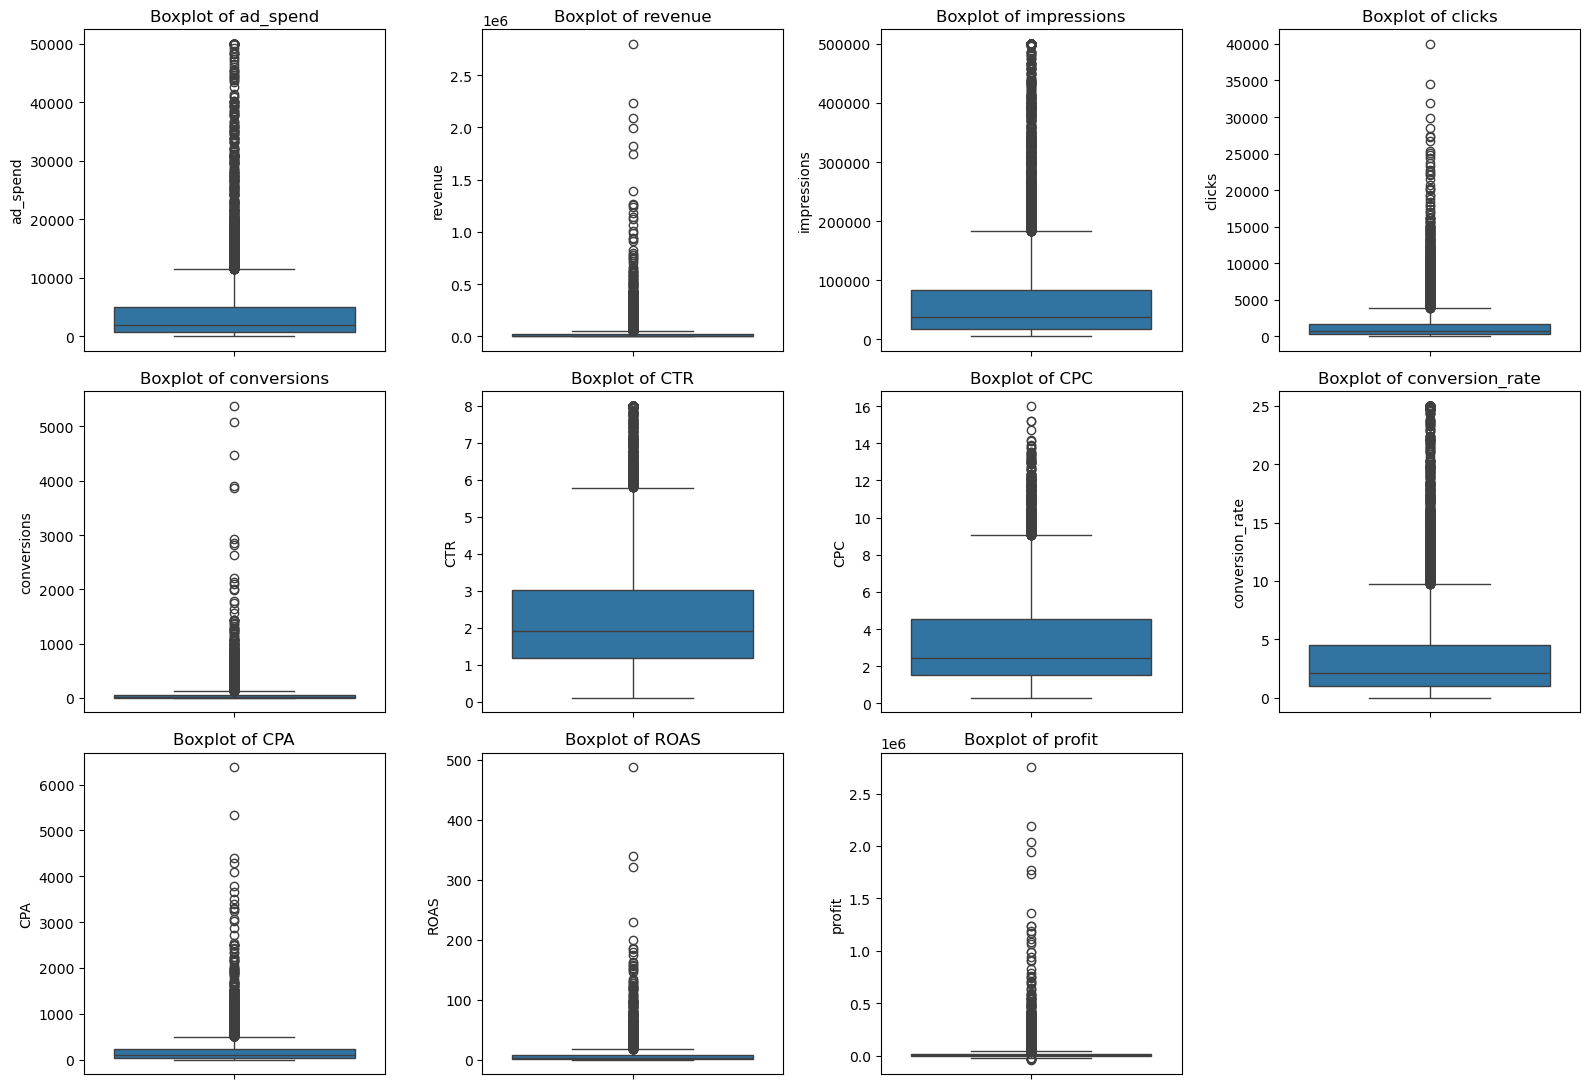

In [24]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i, column in enumerate(important_numeric):
    sns.boxplot(
        data=df,
        y=column,
        ax=axes[i]
    )
    
    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_ylabel(column)

# Hide unused subplot
for j in range(len(important_numeric), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [25]:
outlier_summary = []

for column in important_numeric:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_count = len(outliers)
    outlier_percentage = (outlier_count / len(df)) * 100

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier %": outlier_percentage
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,ad_spend,666.3075,4996.16000,4329.85250,-5828.471250,11490.938750,955,9.55
1,revenue,1608.9100,22165.82500,20556.91500,-29226.462500,53001.197500,1182,11.82
2,impressions,16958.5000,83213.75000,66255.25000,-82424.375000,182596.625000,901,9.01
3,clicks,290.0000,1746.00000,1456.00000,-1894.000000,3930.000000,894,8.94
4,conversions,5.0000,55.00000,50.00000,-70.000000,130.000000,1206,12.06
5,CTR,1.1720,3.01725,1.84525,-1.595875,5.785125,429,4.29
6,CPC,1.5100,4.53000,3.02000,-3.020000,9.060000,336,3.36
7,conversion_rate,1.0050,4.49325,3.48825,-4.227375,9.725625,815,8.15
8,CPA,40.6400,225.45750,184.81750,-236.586250,502.683750,838,8.38
9,ROAS,1.1975,7.95000,6.75250,-8.931250,18.078750,1016,10.16


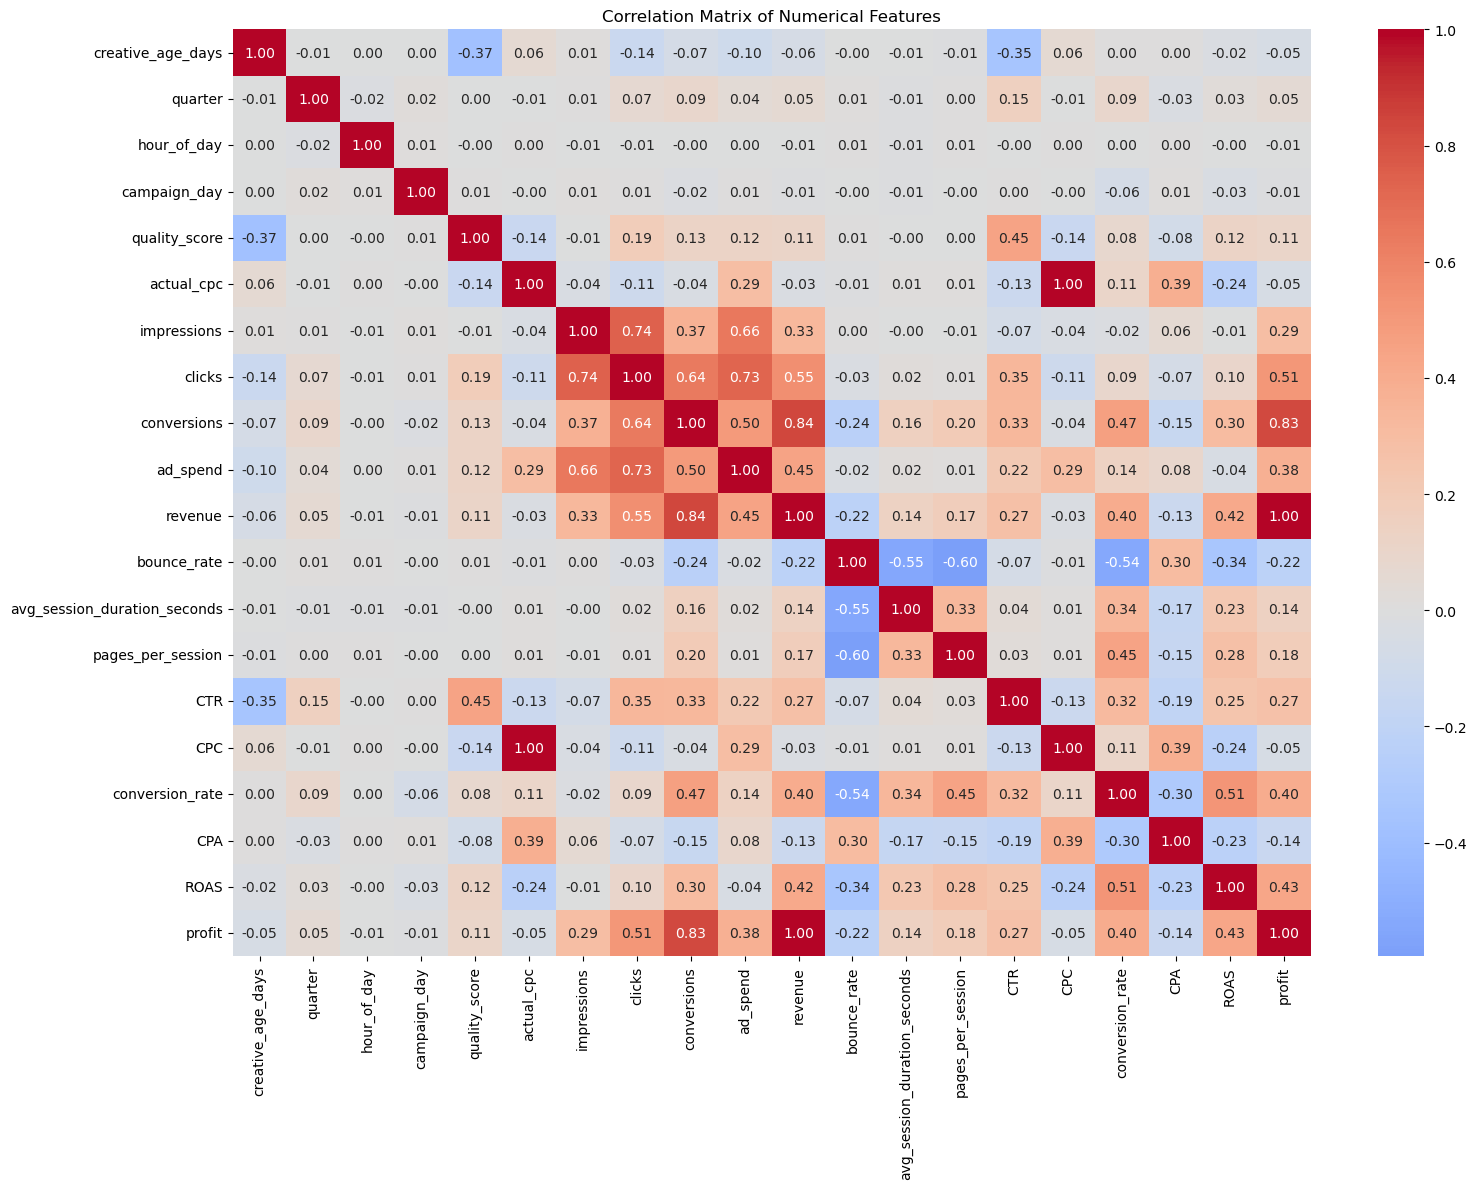

In [26]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

### Correlation Analysis - Observations

The correlation matrix shows several strong relationships among campaign performance variables.

Conversions have a strong positive correlation with revenue (0.84) and profit (0.83). Impressions and clicks also show a strong positive correlation (0.74), while clicks and ad_spend have a correlation of 0.73.

Several website engagement variables show negative relationships with bounce_rate. Bounce_rate has a correlation of -0.60 with pages_per_session and -0.55 with average session duration.

Revenue and profit have a correlation of 1.00 in the dataset, indicating an extremely strong linear relationship between the two variables.

These correlations provide useful insights for feature analysis and will be considered during the preprocessing and modeling stages.

In [27]:
key_targets = [
    "revenue",
    "conversion_rate",
    "ROAS",
    "profit"
]

for target in key_targets:
    print(f"\nCorrelation with {target}:")
    print(
        df[numerical_columns]
        .corr()[target]
        .sort_values(ascending=False)
    )


Correlation with revenue:
revenue                         1.000000
profit                          0.997432
conversions                     0.842255
clicks                          0.551034
ad_spend                        0.446753
ROAS                            0.415478
conversion_rate                 0.400463
impressions                     0.332200
CTR                             0.274617
pages_per_session               0.174071
avg_session_duration_seconds    0.138018
quality_score                   0.112127
quarter                         0.053997
hour_of_day                    -0.005573
campaign_day                   -0.010749
actual_cpc                     -0.028349
CPC                            -0.028349
creative_age_days              -0.058727
CPA                            -0.132980
bounce_rate                    -0.216411
Name: revenue, dtype: float64

Correlation with conversion_rate:
conversion_rate                 1.000000
ROAS                            0.513780
conver

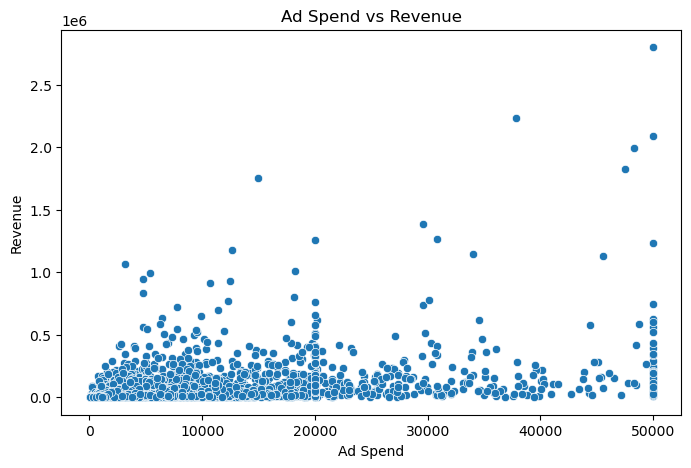

In [28]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="ad_spend",
    y="revenue"
)

plt.title("Ad Spend vs Revenue")
plt.xlabel("Ad Spend")
plt.ylabel("Revenue")

plt.show()

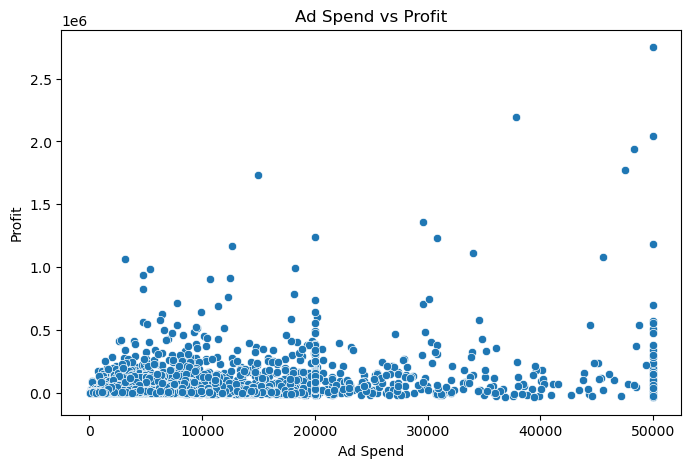

In [29]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="ad_spend",
    y="profit"
)

plt.title("Ad Spend vs Profit")
plt.xlabel("Ad Spend")
plt.ylabel("Profit")

plt.show()

In [30]:
target_columns = [
    "revenue",
    "conversion_rate",
    "ROAS",
    "profit"
]

df[target_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
revenue,10000.0,28415.770647,89284.609131,0.00,1608.9100,6099.2400,22165.82500,2800397.43
conversion_rate,10000.0,3.644033,4.354338,0.00,1.0050,2.1655,4.49325,25.00
ROAS,10000.0,7.524918,14.985237,0.00,1.1975,3.1500,7.95000,487.30
profit,10000.0,24070.204468,86416.098554,-36939.84,209.4800,3302.5350,16641.87750,2750397.93


In [31]:
df["ROI"] = ((df["revenue"] - df["ad_spend"]) / df["ad_spend"]) * 100

df["ROI"].describe()

count    10000.000000
mean       652.494367
std       1498.516912
min       -100.000000
25%         19.679746
50%        214.644531
75%        695.258541
max      48630.026371
Name: ROI, dtype: float64

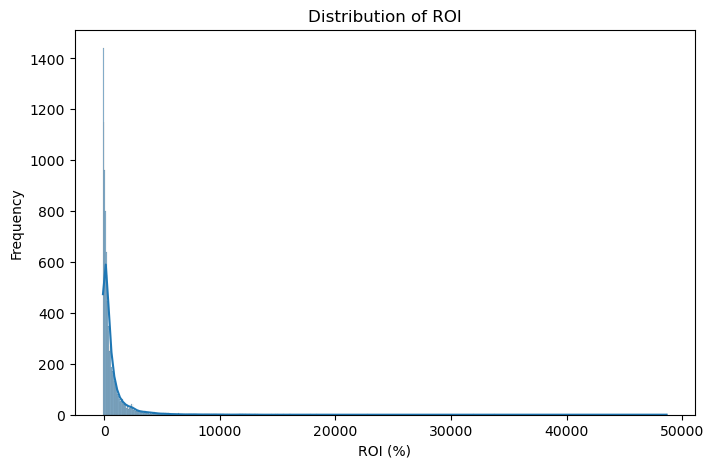

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="ROI",
    kde=True
)

plt.title("Distribution of ROI")
plt.xlabel("ROI (%)")
plt.ylabel("Frequency")

plt.show()

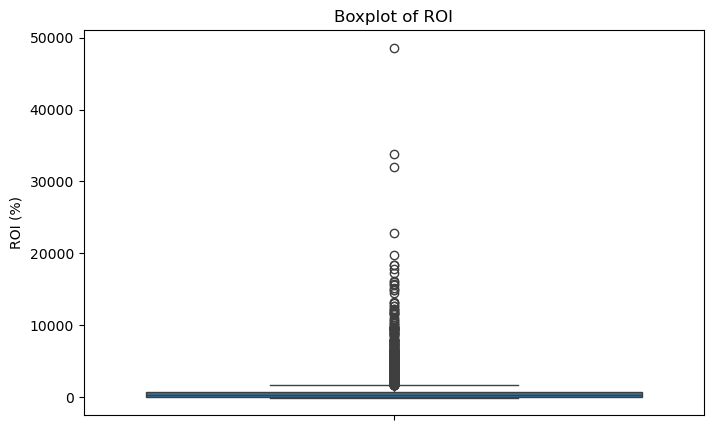

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    y="ROI"
)

plt.title("Boxplot of ROI")
plt.ylabel("ROI (%)")

plt.show()

In [34]:
df.shape

(10000, 42)